In [1]:
# Semente individual usada no projeto.
SEMENTE = 11900

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PASTA = Path.cwd()
if not (PASTA / "dados").exists():  # permite executar a cópia em entrega/
    PASTA = PASTA.parent
CSV = PASTA / "dados/RAIS_VINC_PUB_NORTE.COMT.gz"
PARQUET = PASTA / "dados/RAIS_VINC_PUB_NORTE.COMT.parquet"

# Remunerômetro — RAIS Norte

## 0. Identificação

Autoria: **Letícia Braz Bonfim**

Matrícula: **20240011900**

Semente: **011900**

Prazo da Entrega: **08/11/2026**.

## 1. Pergunta do projeto

- O objetivo é estimar uma referência de remuneração mensal para que o usuario compare cenários de trabalho
- O modelo utiliza características do usuario e do trabalho pretendido
- Por questões de limitações técnicas, a população estimada será apenas o Norte
- O valor previsto é `vl_rem_media_nom`: a remuneração **média mensal nominal** do vínculo durante 2025

**OBS: O resultado ajuda a investigar cenários; não garante o salário de uma vaga**

## 2. Base e exploração inicial

O arquivo original é um CSV comprimido em .gz. Ele ocupa menos espaço em disco, mas uma nova leitura precisa descompactar e percorrer o CSV. O .parquet guarda os dados por coluna e permite utilizar apenas as colunas necessárias.Portanto, o .parquet foi escolhido pela **eficiência de leitura**


In [2]:
# Faz a conversão em pedaços (`chunksize`) apenas se o .parquet ainda não existir
if not PARQUET.exists():
    temporario = PARQUET.with_suffix(".parquet.tmp")
    gravador = None
    for parte in pd.read_csv(CSV, compression="gzip", encoding="latin1",
                             chunksize=32768, low_memory=False):
        # Nomes como "Município - Código" viram "municipio_codigo".
        parte.columns = (parte.columns.str.normalize("NFKD")
                         .str.encode("ascii", "ignore").str.decode("ascii")
                         .str.strip().str.replace("#", "", regex=False)
                         .str.replace(r"[/\.\-]", " ", regex=True)
                         .str.replace(r"[^\w\s]", "", regex=True)
                         .str.lower().str.split().str.join("_"))
        tabela = pa.Table.from_pandas(parte, preserve_index=False)
        if gravador is None:
            gravador = pq.ParquetWriter(temporario, tabela.schema)
        gravador.write_table(tabela)
    gravador.close()
    temporario.replace(PARQUET)

arquivo = pq.ParquetFile(PARQUET)
print(f"Parquet pronto: {arquivo.metadata.num_rows:,} linhas e {arquivo.metadata.num_columns} colunas.")

Parquet pronto: 5,645,037 linhas e 62 colunas.


Para decidir o alvo,avaliamos **apenas as colunas de remuneração**, as candidatas. 

In [3]:
# Leitura inicial das primeiras 5 linhas
remuneracoes = pd.read_parquet(PARQUET, columns=["vl_rem_media_nom", "vl_rem_dezembro_nom"])
remuneracoes.head()

,vl_rem_media_nom,vl_rem_dezembro_nom
0,3009.56,NaN
1,2000.00,NaN
2,1600.00,1600.00
3,1416.20,NaN
4,1570.22,1468.69


In [4]:
# Auditoria das duas remunerações consideradas como alvo
auditoria_nulos_remuneracao = pd.DataFrame({
    "linhas_nulas": remuneracoes.isna().sum(),
    "linhas_nao_nulas": remuneracoes.notna().sum(),
    "percentual_nulas": (remuneracoes.isna().mean() * 100).round(2)
})
auditoria_nulos_remuneracao.sort_values("percentual_nulas", ascending=False)

,linhas_nulas,linhas_nao_nulas,percentual_nulas
vl_rem_dezembro_nom,2338990,3306047,41.43
vl_rem_media_nom,0,5645037,0.00


In [5]:
# Zeros e valores negativos nas duas remunerações consideradas
colunas_remuneracao = [coluna for coluna in remuneracoes.columns if coluna.startswith("vl_rem_")]
auditoria_zeros_e_negativos = pd.DataFrame({
    "linhas_c_zero": (remuneracoes[colunas_remuneracao] == 0).sum(),
    "percentual_zeros": (
        (remuneracoes[colunas_remuneracao] == 0).sum()
        / remuneracoes[colunas_remuneracao].notna().sum() * 100
    ).round(2),
    "linhas_negativas": (remuneracoes[colunas_remuneracao] < 0).sum(),
    "percentual_negativas": (
        (remuneracoes[colunas_remuneracao] < 0).sum()
        / remuneracoes[colunas_remuneracao].notna().sum() * 100
    ).round(2)
})
auditoria_zeros_e_negativos.sort_values("percentual_negativas", ascending=False)

,linhas_c_zero,percentual_zeros,linhas_negativas,percentual_negativas
vl_rem_media_nom,751043,13.3,0,0.0
vl_rem_dezembro_nom,0,0.0,0,0.0


In [6]:
# Descrição estatística geral
remuneracoes.describe().T

,count,mean,std,min,25%,50%,75%,max
vl_rem_media_nom,5645037.0,3014.630904,4152.661810,0.0,1490.29,1985.24,3237.07,216536.68
vl_rem_dezembro_nom,3306047.0,4070.985193,5219.932208,455.4,1759.08,2481.77,4200.00,225727.46


## Definição da variável-alvo

Entre as duas remunerações examinadas, `vl_rem_dezembro_nom` tem **2.338.990 valores ausentes (41,43%)**. `vl_rem_media_nom` não tem valores ausentes.

**Variáveis consideradas:**

- `vl_rem_media_nom`: remuneração média mensal nominal do vínculo no ano, em reais.
- `vl_rem_dezembro_nom`: remuneração nominal de dezembro, com muitos valores ausentes.

**OBS: `vl_rem_media_sm` não foi considerada pois revela a remuneração alvo so que expressa em salários mínimos.**

**Decisão:** prever `vl_rem_media_nom`, um valor numérico em reais; portanto, o problema é de **regressão**. Registros com média mensal igual a zero ficam fora do modelo. Isso define o grupo que queremos estudar, sem concluir que os zeros sejam erros.

In [7]:
ALVO = "vl_rem_media_nom"

Cada linha da base da RAIS representa um vínculo, não necessariamente uma pessoa diferente.

**Exemplo:**

ANA | EMPRESA A | VÍNCULO 1

ANA | EMPRESA B | VÍNCULO 2


In [8]:
remuneracao_positiva = remuneracoes[ALVO] > 0
n_elegiveis = int(remuneracao_positiva.sum())

print(f"""
Total de vínculos: {len(remuneracoes):,}.
Vínculos com remuneração positiva: {n_elegiveis:,}.
Vínculos com remuneração igual a zero: {int((remuneracoes[ALVO] == 0).sum()):,}.
""")

del remuneracoes, remuneracao_positiva


Total de vínculos: 5,645,037.
Vínculos com remuneração positiva: 4,893,994.
Vínculos com remuneração igual a zero: 751,043.



## 3. Amostra, atributos e preparo

O enunciado do professor exige uma amostra de **exatamente 2.000 vínculos**. Esse número não foi escolhido pelo modelo. Ele padroniza o tamanho do treino entre os trabalhos e torna o processamento viável.

1. Separamos 20% dos vínculos elegíveis para o teste final.
2. Dos 80% restantes, sorteamos os 2.000 vínculos exigidos.
3. A validação cruzada de cinco dobras acontece dentro desses 2.000: em cada rodada, 1.600 são usados no `fit()` e 400 na validação com `predict()`.
4. O teste de 20% fica reservado e só recebe `predict()` depois da escolha do modelo.

A mesma semente reproduz a divisão e o sorteio.

In [9]:
# Cria uma posição para cada vínculo com remuneração positiva
todos_os_indices = np.arange(n_elegiveis)

# Separa 80% para desenvolvimento e reserva 20% para o teste final
indices_treino_disponivel, indices_teste = train_test_split(
    todos_os_indices,
    test_size=0.20,
    random_state=SEMENTE
)

# Sorteia, dentro dos 80%, os 2.000 vínculos exigidos pelo professor
indices_amostra = pd.Series(indices_treino_disponivel).sample(
    n=2000,
    random_state=SEMENTE
).to_numpy()

# Marca com True os vínculos do teste para encontrá-los depois na leitura em blocos
no_teste = np.zeros(n_elegiveis, dtype=bool)
no_teste[indices_teste] = True

# Confere que nenhum dos 2.000 vínculos da amostra também está no teste
assert not no_teste[indices_amostra].any()

print(f"""
Treino disponível: {len(indices_treino_disponivel):,}
Amostra exigida para treino e validação: {len(indices_amostra):,}
Teste reservado: {len(indices_teste):,}
""")

# Libera as listas que não serão mais usadas
del todos_os_indices, indices_treino_disponivel, indices_teste


Treino disponível: 3,915,195
Amostra exigida para treino e validação: 2,000
Teste reservado: 978,799



Para não carregar todos os atributos da RAIS de uma vez, a próxima função lê um bloco do Parquet e devolve um `DataFrame` do Pandas com os vínculos de remuneração positiva. 

Ela é usada **duas vezes**: para buscar a amostra e, no fim, para avaliar o teste.

In [10]:
NUMERICAS = ["idade", "qtd_hora_contr"]
CATEGORICAS = ["escolaridade_apos_2005_codigo", "cbo_4_digitos", "municipio_codigo",
               "tipo_vinculo_codigo", "categoria_trabalhador_codigo", "ibge_subsetor_codigo"]
COLUNAS = NUMERICAS + [c for c in CATEGORICAS if c != "cbo_4_digitos"] + [
    "cbo_2002_ocupacao_codigo", ALVO, "sexo_codigo", "raca_cor_codigo"]

# Ler os vinculos em partes
def ler_elegiveis():
    posicao = 0
    for lote in pq.ParquetFile(PARQUET).iter_batches(
            batch_size=16384, columns=COLUNAS, use_threads=False):
        bloco = lote.to_pandas()
        
        salario = bloco[ALVO]
        bloco = bloco.loc[np.isfinite(salario) & salario.gt(0)].copy()
        
        # Redefine indices para que cada vínculo com remuneração positiva tenha um índice único
        bloco.index = np.arange(posicao, posicao + len(bloco))
        posicao += len(bloco)
        yield bloco

In [11]:
partes = []
for bloco in ler_elegiveis():
    selecionados = bloco.loc[bloco.index.isin(indices_amostra)]
    if not selecionados.empty:
        partes.append(selecionados)
amostra = pd.concat(partes).loc[indices_amostra].copy()
assert len(amostra) == 2000
amostra.head()

,idade,qtd_hora_contr,escolaridade_apos_2005_codigo,municipio_codigo,tipo_vinculo_codigo,categoria_trabalhador_codigo,ibge_subsetor_codigo,cbo_2002_ocupacao_codigo,vl_rem_media_nom,sexo_codigo,raca_cor_codigo
1733095,30,43,7,130260,10,101,15,731320,2405.74,1,8
3583659,37,9,9,130260,10,101,23,231210,2135.91,2,8
4028021,66,36,7,120040,10,101,15,517330,2458.98,1,8
3218091,40,44,4,150650,25,101,25,623305,1851.63,1,8
2790040,34,44,7,171820,10,101,21,516305,1027.13,2,8


In [12]:
# Auditoria dos campos usados no modelo e na avaliação, nos 2.000 vínculos de treino
auditoria_nulos_atributos = pd.DataFrame({
    "linhas_nulas": amostra.isna().sum(),
    "linhas_nao_nulas": amostra.notna().sum(),
    "percentual_nulas": (amostra.isna().mean() * 100).round(2)
})
auditoria_nulos_atributos.sort_values("percentual_nulas", ascending=False)

,linhas_nulas,linhas_nao_nulas,percentual_nulas
idade,0,2000,0.0
qtd_hora_contr,0,2000,0.0
escolaridade_apos_2005_codigo,0,2000,0.0
municipio_codigo,0,2000,0.0
tipo_vinculo_codigo,0,2000,0.0
categoria_trabalhador_codigo,0,2000,0.0
ibge_subsetor_codigo,0,2000,0.0
cbo_2002_ocupacao_codigo,0,2000,0.0
vl_rem_media_nom,0,2000,0.0
sexo_codigo,0,2000,0.0


In [13]:
amostra[NUMERICAS + [ALVO]].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
idade,2000.0,37.2405,11.997651,15.0,18.0000,28.00,36.000,45.0000,59.000,68.0000,82.00
qtd_hora_contr,2000.0,42.1090,8.822757,1.0,20.0000,40.00,44.000,44.0000,45.000,99.0000,99.00
vl_rem_media_nom,2000.0,3426.0581,4125.194925,455.4,669.8681,1639.18,2184.475,3481.4825,9692.291,21905.5359,49332.74


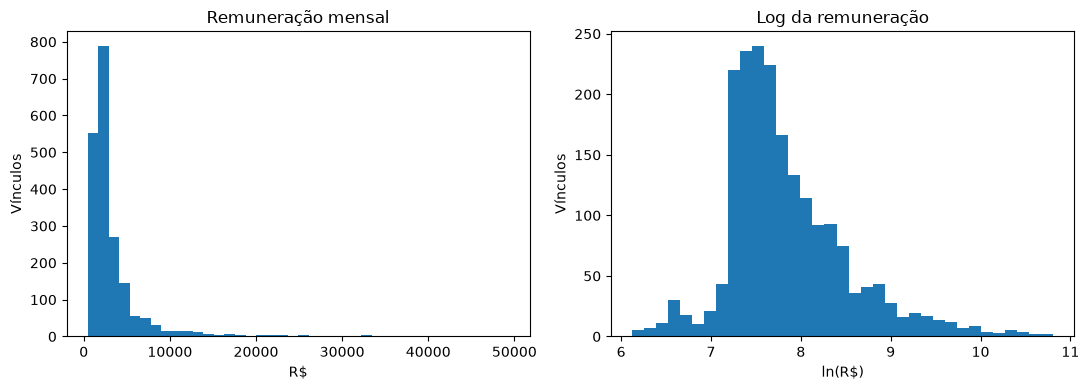

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].hist(amostra[ALVO], bins=40)
eixos[0].set(title="Remuneração mensal", xlabel="R$", ylabel="Vínculos")
eixos[1].hist(np.log(amostra[ALVO]), bins=35)
eixos[1].set(title="Log da remuneração", xlabel="ln(R$)", ylabel="Vínculos")
fig.tight_layout()
plt.show()

In [15]:
cbo = amostra["cbo_2002_ocupacao_codigo"].astype("Int64").astype("string").str.zfill(6)
comparacao_cbo = []
for digitos in [2, 4, 6]:
    frequencia = cbo.str[:digitos].value_counts()
    comparacao_cbo.append({"dígitos": digitos, "ocupações": len(frequencia),
                           "vínculos em ocupações com menos de 5 casos": int(frequencia[frequencia < 5].sum())})
pd.DataFrame(comparacao_cbo)

,dígitos,ocupações,vínculos em ocupações com menos de 5 casos
0,2,45,19
1,4,271,326
2,6,455,561


Usaremos oito características: **idade e jornada** como números; **escolaridade, ocupação CBO com quatro dígitos, município do estabelecimento, tipo de vínculo, categoria do trabalhador e subsetor** como categorias. CBO com quatro dígitos evita dividir demais a pequena amostra. Tipo e categoria são parecidos, mas a decisão da rodada avaliada foi manter ambos; a análise posterior dessa semelhança está no registro 02.

Sexo e raça/cor ficam fora dos preditores. Sexo será usado só para conferir erros por grupo. Tempo no emprego e qualquer coluna de remuneração também ficam fora, pois não descrevem um cenário disponível antes de uma contratação. Os códigos especiais não foram transformados em ausências sem definição confirmada.

| Característica usada | Como entra |
|---|---|
| Idade | Número |
| Jornada contratada | Número |
| Escolaridade | Categoria |
| Ocupação CBO (4 dígitos) | Categoria |
| Município do estabelecimento | Categoria |
| Tipo de vínculo | Categoria |
| Categoria do trabalhador | Categoria |
| Subsetor IBGE | Categoria |

`StandardScaler` coloca idade e jornada em escalas comparáveis. `OneHotEncoder` transforma cada código de categoria em uma coluna de 0 ou 1.


In [16]:
def preparar_atributos(dados):
    """Mesmo preparo para a amostra e para cada bloco do teste."""
    x = dados[NUMERICAS + [c for c in CATEGORICAS if c != "cbo_4_digitos"]].copy()
    x["cbo_4_digitos"] = (dados["cbo_2002_ocupacao_codigo"].astype("Int64")
                          .astype("string").str.zfill(6).str[:4])
    for nome in CATEGORICAS:
        if nome != "cbo_4_digitos":
            x[nome] = x[nome].astype("Int64").astype("string")
        x[nome] = x[nome].astype(object).where(x[nome].notna(), np.nan)
    return x[NUMERICAS + CATEGORICAS]

X = preparar_atributos(amostra)
y = np.log(amostra[ALVO].to_numpy())
assert ALVO not in X.columns
X.head()

,idade,qtd_hora_contr,escolaridade_apos_2005_codigo,cbo_4_digitos,municipio_codigo,tipo_vinculo_codigo,categoria_trabalhador_codigo,ibge_subsetor_codigo
1733095,30,43,7,7313,130260,10,101,15
3583659,37,9,9,2312,130260,10,101,23
4028021,66,36,7,5173,120040,10,101,15
3218091,40,44,4,6233,150650,25,101,25
2790040,34,44,7,5163,171820,10,101,21


In [17]:
preparo = ColumnTransformer([
    ("numericas", StandardScaler(), NUMERICAS),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=True), CATEGORICAS)
], sparse_threshold=1.0)

## 4. Modelos e validação cruzada

O **baseline** é uma referência simples: ele prevê a mediana da remuneração para todos os vínculos. Um modelo só é útil se conseguir errar menos que essa referência.

MQO, Ridge e Lasso aprendem relações entre os atributos e o log da remuneração. 
- MQO minimiza os erros ao quadrado
- Ridge faz isso e também penaliza coeficientes muito grandes
- Lasso aplica uma penalização que pode zerar alguns coeficientes, o `alpha` controla a força dessa penalização.

Em cada uma das cinco dobras, o Pipeline aprende o preparo e o modelo com 1.600 vínculos (`fit()`) e faz previsões nos 400 restantes (`predict()`). Repetimos isso até que todos os vínculos sejam validados uma vez.

O **MAE em reais** é o erro principal: mostra, em média, quantos reais a previsão se afasta do valor observado. O **RMSE em log** é complementar e dá mais peso aos erros grandes na escala logarítmica.

Usamos o log no treinamento para trabalhar com uma escala mais adequada às remunerações muito diferentes. Depois, `exp` transforma a previsão de volta para reais. O `alpha` é escolhido pela validação cruzada, sem olhar o teste. A grade testa 16 valores no Ridge e 13 no Lasso; os melhores ficaram dentro das grades.

In [18]:
def mae_em_reais(estimador, x, y_real_log):
    return -mean_absolute_error(np.exp(y_real_log), np.exp(estimador.predict(x)))

cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
modelos = {
    "Baseline": (DummyRegressor(strategy="median"), {}),
    "MQO": (Pipeline([("preparo", preparo), ("modelo", LinearRegression(tol=1e-8))]), {}),
    "Ridge": (Pipeline([("preparo", preparo), ("modelo", Ridge(solver="lsqr", tol=1e-8, max_iter=20000))]),
              {"modelo__alpha": np.logspace(-2, 3, 16)}),
    "Lasso": (Pipeline([("preparo", preparo), ("modelo", Lasso(max_iter=100000, tol=1e-6))]),
              {"modelo__alpha": np.logspace(-5, -1, 13)}),
}

buscas = {}
for nome, (modelo, grade) in modelos.items():
    busca = GridSearchCV(modelo, grade,
                         scoring={"mae_reais": mae_em_reais, "rmse_log": "neg_root_mean_squared_error"},
                         refit="mae_reais", cv=cv, return_train_score=True,
                         n_jobs=1, error_score="raise")
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        busca.fit(X, y)
    buscas[nome] = busca
    print(f"{nome}: MAE na validação = R$ {-busca.best_score_:,.2f}; parâmetros = {busca.best_params_}")

# As duas grades precisam conter o melhor alpha longe das pontas.
for nome in ["Ridge", "Lasso"]:
    grade = modelos[nome][1]["modelo__alpha"]
    if buscas[nome].best_params_["modelo__alpha"] in [grade[0], grade[-1]]:
        raise ValueError(f"Amplie a grade de {nome} antes de usar o teste.")
MODELO_FINAL = min(buscas, key=lambda nome: -buscas[nome].best_score_)
print("Escolhido sem olhar o teste:", MODELO_FINAL)

Baseline: MAE na validação = R$ 1,809.19; parâmetros = {}
MQO: MAE na validação = R$ 1,386.99; parâmetros = {}
Ridge: MAE na validação = R$ 1,369.17; parâmetros = {'modelo__alpha': np.float64(4.6415888336127775)}
Lasso: MAE na validação = R$ 1,371.74; parâmetros = {'modelo__alpha': np.float64(0.00046415888336127773)}
Escolhido sem olhar o teste: Ridge


In [19]:
linhas = []
for nome, busca in buscas.items():
    resultado = busca.cv_results_
    i = busca.best_index_
    previsto_treino = busca.predict(X)
    linhas.append({"modelo": nome,
                  "alpha": busca.best_params_.get("modelo__alpha"),
                  "MAE_treino_R$": mean_absolute_error(amostra[ALVO], np.exp(previsto_treino)),
                  "MAE_CV_R$": -resultado["mean_test_mae_reais"][i],
                  "desvio_MAE_CV_R$": resultado["std_test_mae_reais"][i],
                  "RMSE_treino_log": np.sqrt(np.mean((y - previsto_treino)**2)),
                  "RMSE_CV_log": -resultado["mean_test_rmse_log"][i]})
tabela_cv = pd.DataFrame(linhas)
tabela_cv

,modelo,alpha,MAE_treino_R$,MAE_CV_R$,desvio_MAE_CV_R$,RMSE_treino_log,RMSE_CV_log
0,Baseline,NaN,1808.961920,1809.193441,190.860304,0.689378,0.688222
1,MQO,NaN,1253.129552,1386.993181,140.294621,0.414487,0.466874
2,Ridge,4.641589,1269.462362,1369.169368,127.919823,0.420221,0.460447
3,Lasso,0.000464,1268.618109,1371.740771,132.751949,0.421301,0.460742


**Ridge foi escolhido pelo menor MAE na validação cruzada.** Ele também teve o menor desvio entre as dobras dos três modelos lineares. MQO e Lasso erraram menos no treino, mas mais na validação, o que sugere maior sobreajuste.

## 5. Sobreajuste

Depois do preparo, há 209 colunas para 2.000 vínculos (`p/n = 0,1045`).

Comparamos o erro no treino e nas partes deixadas de fora em cada dobra. Se um modelo funciona muito melhor no treino, pode não funcionar tão bem em novos vínculos. `alpha` controla a força da penalização de Ridge e Lasso. O gráfico mostra onde cada um teve menor erro de validação.

**O que o gráfico mostrou:** no Ridge escolhido (alpha 4,64), o MAE da validação ficou cerca de R$ 98 acima do erro no treino das dobras. Com alpha 1.000, os dois erros aumentaram: a penalização ficou forte demais. Isso ajuda a entender por que o melhor ponto ficou no meio da grade.


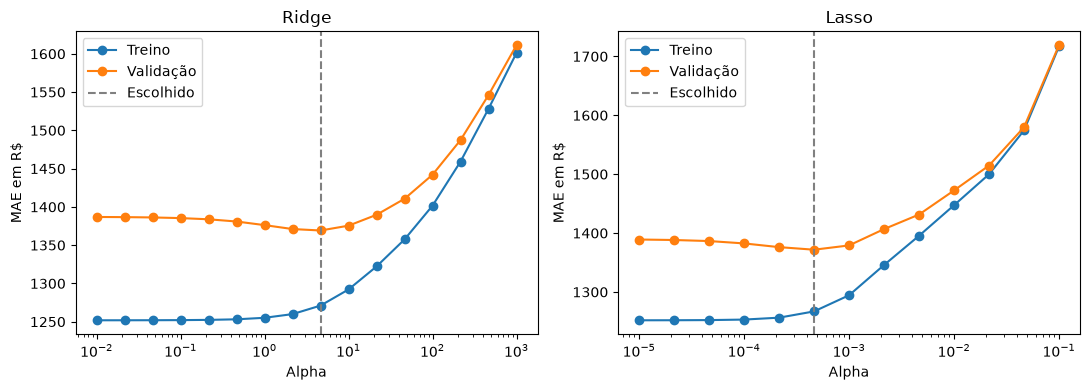

Colunas após o preparo: 209


In [20]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for eixo, nome in zip(eixos, ["Ridge", "Lasso"]):
    busca = buscas[nome]
    r = busca.cv_results_
    alpha = np.asarray(r["param_modelo__alpha"], dtype=float)
    ordem = np.argsort(alpha)
    eixo.plot(alpha[ordem], -np.asarray(r["mean_train_mae_reais"])[ordem], "o-", label="Treino")
    eixo.plot(alpha[ordem], -np.asarray(r["mean_test_mae_reais"])[ordem], "o-", label="Validação")
    eixo.axvline(busca.best_params_["modelo__alpha"], color="gray", linestyle="--", label="Escolhido")
    eixo.set(xscale="log", title=nome, xlabel="Alpha", ylabel="MAE em R$")
    eixo.legend()
fig.tight_layout()
plt.show()
print("Colunas após o preparo:", buscas["Ridge"].best_estimator_.named_steps["preparo"].transform(X).shape[1])

## 6. Teste reservado

A rodada original já escolheu **Ridge** antes de usar o teste. Os valores abaixo registram essa escolha: 2.000 vínculos na amostra, 978.799 no teste e os alphas da validação. Se uma nova execução escolher algo diferente, ela para aqui. A avaliação a seguir apenas **reproduz o procedimento fixado**; o vencedor não muda pelo resultado do teste.

In [21]:
assert len(amostra) == 2000 and n_elegiveis == 4893994 and int(no_teste.sum()) == 978799
assert MODELO_FINAL == "Ridge"
assert buscas["Ridge"].best_params_["modelo__alpha"] == 4.6415888336127775
assert buscas["Lasso"].best_params_["modelo__alpha"] == 0.00046415888336127773
print("Escolha original conferida. Agora o teste pode ser avaliado sem selecionar outro modelo.")

Escolha original conferida. Agora o teste pode ser avaliado sem selecionar outro modelo.


O teste tem quase um milhão de vínculos. O cálculo abaixo lê um bloco, faz as previsões e **soma os erros**. Assim não guarda todas as previsões na memória. A tabela de erros por escolaridade e sexo usa apenas o Ridge escolhido.

In [22]:
nomes = list(buscas)
somas = pd.DataFrame(0.0, index=nomes,
                     columns=["n", "erro_abs", "erro_quadrado_log", "erro", "observado", "previsto"])
grupos_parciais = []

for bloco in ler_elegiveis():
    teste_bloco = bloco.loc[no_teste[bloco.index]]
    if teste_bloco.empty:
        continue
    x_bloco = preparar_atributos(teste_bloco)
    observado = teste_bloco[ALVO].to_numpy()

    for nome, busca in buscas.items():
        previsao_log = busca.best_estimator_.predict(x_bloco)
        previsto = np.exp(previsao_log)
        erro = previsto - observado
        quadrado_log = (previsao_log - np.log(observado))**2
        somas.loc[nome] += [len(observado), np.abs(erro).sum(), quadrado_log.sum(),
                            erro.sum(), observado.sum(), previsto.sum()]

        if nome == MODELO_FINAL:
            for variavel in ["escolaridade_apos_2005_codigo", "sexo_codigo"]:
                dados_grupo = pd.DataFrame({
                    "grupo": teste_bloco[variavel].astype("Int64").astype("string").fillna("[ausente]").to_numpy(),
                    "erro_abs": np.abs(erro), "quadrado_log": quadrado_log,
                    "erro": erro, "observado": observado, "previsto": previsto})
                resumo = dados_grupo.groupby("grupo").agg(
                    n=("erro_abs", "size"), erro_abs=("erro_abs", "sum"),
                    quadrado_log=("quadrado_log", "sum"), erro=("erro", "sum"),
                    observado=("observado", "sum"), previsto=("previsto", "sum")).reset_index()
                resumo["variavel"] = variavel
                grupos_parciais.append(resumo)

assert somas["n"].eq(978799).all()

In [23]:
teste = pd.DataFrame({
    "modelo": somas.index,
    "MAE_teste_R$": somas["erro_abs"].to_numpy() / somas["n"].to_numpy(),
    "RMSE_teste_log": np.sqrt(somas["erro_quadrado_log"].to_numpy() / somas["n"].to_numpy()),
    "erro_medio_R$": somas["erro"].to_numpy() / somas["n"].to_numpy()})
comparacao = tabela_cv.merge(teste, on="modelo")
comparacao

,modelo,alpha,MAE_treino_R$,MAE_CV_R$,desvio_MAE_CV_R$,RMSE_treino_log,RMSE_CV_log,MAE_teste_R$,RMSE_teste_log,erro_medio_R$
0,Baseline,NaN,1808.961920,1809.193441,190.860304,0.689378,0.688222,1865.523773,0.702980,-1294.611387
1,MQO,NaN,1253.129552,1386.993181,140.294621,0.414487,0.466874,1374.009160,0.468700,-544.631662
2,Ridge,4.641589,1269.462362,1369.169368,127.919823,0.420221,0.460447,1374.791198,0.465289,-588.995540
3,Lasso,0.000464,1268.618109,1371.740771,132.751949,0.421301,0.460742,1373.297524,0.466337,-585.609398


In [24]:
ganho = (teste.loc[teste.modelo.eq("Baseline"), "MAE_teste_R$"].iloc[0]
         - teste.loc[teste.modelo.eq(MODELO_FINAL), "MAE_teste_R$"].iloc[0])
ganho /= teste.loc[teste.modelo.eq("Baseline"), "MAE_teste_R$"].iloc[0]
print(f"Ridge: MAE no teste = R$ {teste.loc[teste.modelo.eq(MODELO_FINAL), 'MAE_teste_R$'].iloc[0]:,.2f}.")
print(f"Redução do MAE em relação à mediana constante: {ganho:.2%}.")
print("A escolha continua sendo Ridge, feita antes do teste.")

Ridge: MAE no teste = R$ 1,374.79.
Redução do MAE em relação à mediana constante: 26.31%.
A escolha continua sendo Ridge, feita antes do teste.


In [25]:
grupos = (pd.concat(grupos_parciais)
          .groupby(["variavel", "grupo"], as_index=False)
          [["n", "erro_abs", "quadrado_log", "erro", "observado", "previsto"]].sum())
grupos["MAE_R$"] = grupos["erro_abs"] / grupos["n"]
grupos["RMSE_log"] = np.sqrt(grupos["quadrado_log"] / grupos["n"])
grupos["media_observada_R$"] = grupos["observado"] / grupos["n"]
grupos["erro_relativo_%"] = 100 * grupos["MAE_R$"] / grupos["media_observada_R$"]
assert grupos.groupby("variavel")["n"].sum().eq(978799).all()
grupos[["variavel", "grupo", "n", "MAE_R$", "RMSE_log", "media_observada_R$", "erro_relativo_%"]]

,variavel,grupo,n,MAE_R$,RMSE_log,media_observada_R$,erro_relativo_%
0,escolaridade_apos_2005_codigo,1,5510,976.613578,0.416897,2872.796584,33.995222
1,escolaridade_apos_2005_codigo,10,4782,5929.552104,0.807703,10308.850176,57.519044
2,escolaridade_apos_2005_codigo,11,4501,5711.604923,0.720650,10927.381595,52.268742
3,escolaridade_apos_2005_codigo,2,15932,666.919002,0.372693,2197.741951,30.345646
4,escolaridade_apos_2005_codigo,3,8884,702.309646,0.382526,2349.931762,29.886385
5,escolaridade_apos_2005_codigo,4,30696,683.230502,0.392632,2334.114429,29.271508
6,escolaridade_apos_2005_codigo,5,56429,725.600986,0.396458,2423.861982,29.935739
7,escolaridade_apos_2005_codigo,6,43713,575.726803,0.390744,1987.236645,28.971225
8,escolaridade_apos_2005_codigo,7,546442,759.252491,0.387387,2461.965050,30.839288
9,escolaridade_apos_2005_codigo,8,21542,1073.660948,0.467226,2820.400276,38.067680


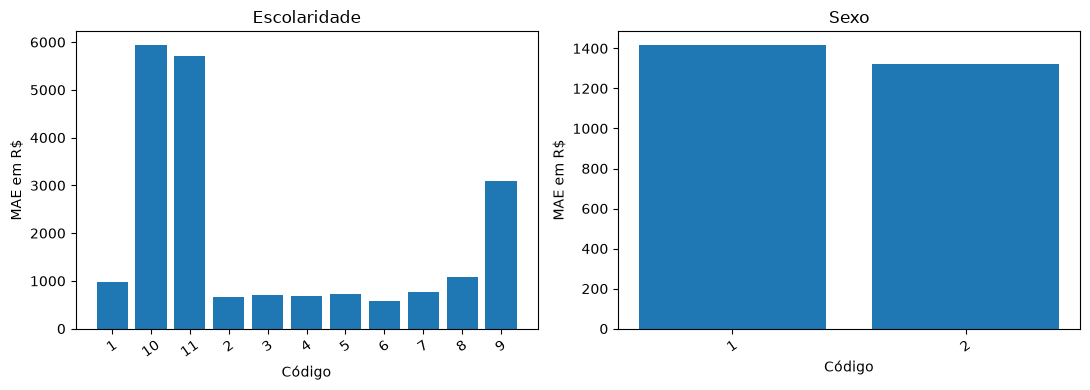

In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for eixo, variavel, titulo in zip(eixos,
        ["escolaridade_apos_2005_codigo", "sexo_codigo"], ["Escolaridade", "Sexo"]):
    parte = grupos.loc[grupos.variavel.eq(variavel)]
    eixo.bar(parte["grupo"], parte["MAE_R$"])
    eixo.set(title=titulo, xlabel="Código", ylabel="MAE em R$")
    eixo.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

## 7. O que concluímos e limites

Ridge foi escolhido pelas cinco dobras de validação. No teste fixado, seu MAE é cerca de **R$ 1.375**: em média, a distância entre valor previsto e observado foi desse tamanho. O modelo melhorou em relação a prever a mesma mediana para todos, mas o erro ainda é grande para prometer um salário individual. O resultado do Lasso no teste não muda a escolha feita antes.

Os dados representam vínculos formais da RAIS 2025 Norte com remuneração média mensal positiva. Não representam todas as pessoas nem todas as vagas; não medem o efeito de trocar de profissão ou cidade. Alguns códigos atuais ainda não têm definição confirmada, e não há teste com outro ano ou região. Sexo não entrou no modelo, mas isso não garante ausência de diferenças de erro entre grupos.

**Critério do Ridge:** para `z = ln(remuneração)`, o modelo minimiza `Σ(zᵢ − b₀ − Xᵢβ)² + αΣβⱼ²`. O `alpha` foi escolhido nas cinco dobras, antes do teste.

**Uso de IA:** Codex/OpenAI ajudou a organizar e programar o notebook além de escrever a documentação. A validação final/revisão e execução técnica foi feita por mim.

**Arquivos acadêmicos:** `REM_20240011900_Leticia.ipynb` executado e `REM_20240011900_Leticia.html`.

**Repositório do projeto:** [LeticiaBrazBonfim/remunerometro-rais-norte](https://github.com/LeticiaBrazBonfim/remunerometro-rais-norte).

**Erro por Grupo:** Também foi analisado o erro por grupo para verificar se o modelo é igualmente preciso em diferentes perfis. No teste, o MAE foi de R$ 1.414,48 para o código de sexo 1 e R$ 1.322,83 para o código 2. O código de escolaridade 10 teve MAE maior, mas também apresentou remuneração média mais alta. Essas diferenças descrevem o desempenho do modelo e não provam relações causais.